# Лабораторная работа № 1
## Решение варианта № 8

**Дисциплина:** «Методы анализа больших данных»  
**Профиль:** «Информатика и английский язык»  
**Среда:** Google Colab, Python 3.10+

### Постановка задачи

Для учащихся с `lunch == "standard"` сравнить сводный показатель успеваемости (Math, Reading, Writing) у двух групп:
- подготовительный курс пройден — `completed`;
- подготовительный курс не пройден — `none`.

Сводный показатель — среднее арифметическое трёх результатов: `math score`, `reading score`, `writing score`. Пропуски обрабатываются средним значением соответствующего числового столбца, потенциальные выбросы выявляются по Z-score.

**Гипотеза (EN):** Among students with standard lunch, completed test preparation is associated with a higher overall mean score.  
**Гипотеза (RU):** Среди учащихся со standard lunch подготовительный курс связан с более высоким средним общим результатом.

**Тема школьного микроурока:** «Сводный показатель успеваемости».


## Блок 1. Импорт библиотек и прямая загрузка датасета

Основной URL берётся строго из условия лабораторной работы. Если он недоступен по сетевой или HTTP-причине, код автоматически обращается к резервному публичному URL на тот же `StudentsPerformance.csv`.

Ручная загрузка файла в Colab не используется.


In [ ]:
import io
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PRIMARY_URL = "https://raw.githubusercontent.com/sriharikadali/Students-Performance-in-Exams/master/StudentsPerformance.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv"


def load_students_performance(primary_url: str, fallback_url: str):
    """
    Загружает CSV непосредственно по HTTPS.
    Сначала используется URL из задания, затем резервный URL.
    """
    errors = []

    for url in (primary_url, fallback_url):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                raw_bytes = response.read()

            dataframe = pd.read_csv(io.BytesIO(raw_bytes))

            required_columns = {
                "gender",
                "race/ethnicity",
                "parental level of education",
                "lunch",
                "test preparation course",
                "math score",
                "reading score",
                "writing score",
            }

            missing_columns = required_columns - set(dataframe.columns)
            if missing_columns:
                raise ValueError(
                    f"Отсутствуют обязательные столбцы: {sorted(missing_columns)}"
                )

            return dataframe, url

        except Exception as exc:
            errors.append(
                f"{url} -> {type(exc).__name__}: {exc}"
            )

    raise RuntimeError(
        "Не удалось загрузить датасет.\n" + "\n".join(errors)
    )


df_raw, USED_URL = load_students_performance(PRIMARY_URL, FALLBACK_URL)

print("Dataset loaded successfully / Датасет успешно загружен")
print("Used URL / Использованный URL:")
print(USED_URL)
print("Shape / Размер:", df_raw.shape)

display(df_raw.head())


Dataset loaded successfully / Датасет успешно загружен
Used URL / Использованный URL:
https://raw.githubusercontent.com/NadavKiani/Students-Performance-in-Exams/master/StudentsPerformance.csv
Shape / Размер: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Загружен датасет из **1000 строк и 8 столбцов**. Использован резервный URL, потому что основной адрес во время запуска оказался недоступен. Структура файла соответствует условию лабораторной работы.

## Блок 2. Первичная проверка и контроль качества

Проверяются:

- структура таблицы;
- типы данных;
- пропуски $NaN$;
- полные дубликаты;
- диапазон баллов 0–100;
- значения категориальных полей.

Доля пропусков:

$$
r_{miss}=\frac{N_{miss}}{N}.
$$


In [ ]:
score_cols = ["math score", "reading score", "writing score"]

categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
]

print("Rows, columns / Строки, столбцы:", df_raw.shape)

print("\n--- INFO ---")
df_raw.info()

print("\n--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---")
display(df_raw.head())

missing_report = df_raw.isna().sum().to_frame("missing_count")
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(df_raw) * 100
)

print("\n--- MISSING VALUES / ПРОПУСКИ ---")
display(missing_report)

duplicate_count = int(df_raw.duplicated().sum())
print("Exact duplicates / Полные дубликаты:", duplicate_count)

print("\n--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---")
display(df_raw[score_cols].describe().T)

range_check = pd.DataFrame({
    "below_0": (df_raw[score_cols] < 0).sum(),
    "above_100": (df_raw[score_cols] > 100).sum(),
})

print("\n--- RANGE CHECK 0..100 / ПРОВЕРКА ДИАПАЗОНА ---")
display(range_check)

for col in categorical_cols:
    print(f"\nColumn / Столбец: {col}")
    display(df_raw[col].value_counts(dropna=False).to_frame("count"))


Rows, columns / Строки, столбцы: (1000, 8)

--- INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

--- FIRST ROWS / ПЕРВЫЕ СТРОКИ ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- MISSING VALUES / ПРОПУСКИ ---


,missing_count,missing_percent
gender,0,0.0
race/ethnicity,0,0.0
parental level of education,0,0.0
lunch,0,0.0
test preparation course,0,0.0
math score,0,0.0
reading score,0,0.0
writing score,0,0.0


Exact duplicates / Полные дубликаты: 0

--- NUMERIC DESCRIPTION / ЧИСЛОВАЯ СТАТИСТИКА ---


...

,count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



Column / Столбец: lunch


,count
lunch,
standard,645
free/reduced,355



Column / Столбец: test preparation course


,count
test preparation course,
none,642
completed,358


### Короткое пояснение результата

В исходных данных **нет пропусков и полных дубликатов**. Все три экзаменационных балла находятся в допустимом диапазоне **0–100**. Значит, дополнительного исправления пропусков для этого запуска не требуется, но код обработки оставлен как часть воспроизводимого конвейера.

### Обработка пропусков варианта № 8

Применяем выбранное для варианта правило:
- числовые показатели успеваемости → среднее арифметическое соответствующего столбца;
- категориальные поля → мода.

Исходный `df_raw` не изменяется. Если в исходном датасете пропусков нет, импутация не меняет значения.


In [ ]:
df = df_raw.copy()

# Удаление полных дублей, если они есть.
n_before = len(df)
df = df.drop_duplicates().copy()
n_after = len(df)

print(
    "Removed exact duplicates / Удалено полных дублей:",
    n_before - n_after
)

# Импутация числовых полей средним арифметическим.
for col in score_cols:
    missing_before = int(df[col].isna().sum())
    mean_value = df[col].mean()

    df[col] = df[col].fillna(mean_value)

    print(
        f"{col}: NaN before={missing_before}; "
        f"mean={mean_value:.2f}"
    )

# Импутация модой категориальных полей.
for col in categorical_cols:
    missing_before = int(df[col].isna().sum())

    if missing_before > 0:
        mode_series = df[col].mode(dropna=True)

        if mode_series.empty:
            raise ValueError(
                f"Невозможно определить моду для столбца {col}"
            )

        mode_value = mode_series.iloc[0]
        df[col] = df[col].fillna(mode_value)
    else:
        mode_value = "not required / не требуется"

    print(
        f"{col}: NaN before={missing_before}; "
        f"mode={mode_value}"
    )

print("\nNaN after imputation / Пропуски после импутации:")
display(df.isna().sum().to_frame("missing_count"))


Removed exact duplicates / Удалено полных дублей: 0
math score: NaN before=0; mean=66.09
reading score: NaN before=0; mean=69.17
writing score: NaN before=0; mean=68.05
gender: NaN before=0; mode=not required / не требуется
race/ethnicity: NaN before=0; mode=not required / не требуется
parental level of education: NaN before=0; mode=not required / не требуется
lunch: NaN before=0; mode=not required / не требуется
test preparation course: NaN before=0; mode=not required / не требуется

NaN after imputation / Пропуски после импутации:


,missing_count
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


### Короткое пояснение результата

Пропуски в числовых столбцах заполняются средним значением соответствующего столбца, категориальные пропуски — модой. Если пропусков нет, фактические значения не изменяются.


## Блок 3. Поиск и обработка выбросов методом Z-score

Для каждого из трёх экзаменационных показателей вычисляется стандартизированное отклонение:

$$z = \frac{x-\mu}{\sigma}.$$

Потенциальным выбросом считается значение, для которого $|z| > 3$. Строка исключается из очищенной таблицы, если хотя бы один из трёх баллов является потенциальным выбросом.

Низкий или высокий результат не обязательно является ошибкой; в реальном исследовании такие наблюдения следует дополнительно проверять.


In [ ]:
z_scores = pd.DataFrame(index=df.index)
outlier_mask = pd.Series(False, index=df.index)
z_threshold = 3

for col in score_cols:
    std_value = df[col].std(ddof=0)
    mean_value = df[col].mean()

    if std_value == 0 or pd.isna(std_value):
        z_scores[col] = 0.0
    else:
        z_scores[col] = (df[col] - mean_value) / std_value

    current_outliers = z_scores[col].abs() > z_threshold
    outlier_mask = outlier_mask | current_outliers

z_report = pd.DataFrame({
    "mean": df[score_cols].mean(),
    "std": df[score_cols].std(ddof=0),
    "outlier_count": (z_scores.abs() > z_threshold).sum()
})
display(z_report.round(3))

print(
    f"Rows with >=1 Z-score outlier (|z| > {z_threshold}) / "
    "Строк с хотя бы одним выбросом:",
    int(outlier_mask.sum())
)

df_clean = df.loc[~outlier_mask].copy()

print("Rows before / Строк до очистки:", len(df))
print("Rows after / Строк после очистки:", len(df_clean))
print("Removed / Удалено:", len(df) - len(df_clean))

assert df_clean[score_cols].notna().all().all()
assert (((df_clean[score_cols] >= 0) & (df_clean[score_cols] <= 100)).all().all())
display(df_clean.head())


,mean,std,outlier_count
math score,66.089,15.155,4
reading score,69.169,14.593,4
writing score,68.054,15.188,4


Rows with >=1 Z-score outlier (|z| > 3) / Строк с хотя бы одним выбросом: 7
Rows before / Строк до очистки: 1000
Rows after / Строк после очистки: 993
Removed / Удалено: 7


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### Короткое пояснение результата

Метод Z-score выявляет потенциальные выбросы по правилу $|z|>3$. Метод отметил **7** строк как содержащие хотя бы один потенциальный выброс. После учебной очистки осталось **993** строки. Наблюдения удаляются только для последующего учебного анализа; это не означает, что необычный балл обязательно ошибочен.


### Дополнительная демонстрация Min-Max нормализации

Исходные баллы сохраняются, а нормализованные значения создаются в новых столбцах:

$$
x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}.
$$


In [ ]:
df_normalized = df_clean.copy()

for col in score_cols:
    x_min = df_clean[col].min()
    x_max = df_clean[col].max()

    if x_max == x_min:
        df_normalized[col + "_norm"] = 0.0
    else:
        df_normalized[col + "_norm"] = (
            (df_clean[col] - x_min) /
            (x_max - x_min)
        )

norm_cols = [col + "_norm" for col in score_cols]
display(df_normalized[norm_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
math score_norm,993.0,0.569499,0.187973,0.0,0.448718,0.564103,0.705128,1.0
reading score_norm,993.0,0.575990,0.197067,0.0,0.444444,0.583333,0.722222,1.0
writing score_norm,993.0,0.566900,0.201633,0.0,0.424658,0.575342,0.712329,1.0


### Короткое пояснение результата

После Min-Max нормализации значения каждого экзаменационного показателя находятся в диапазоне **0–1**. В варианте № 8 нормализованные столбцы используются только как демонстрация и не заменяют исходные баллы при проверке гипотезы.

### Фильтрация варианта № 8 и создание сводного показателя

Оставляем учащихся со `standard` lunch. Для каждого учащегося рассчитываем `overall_mean_score` — среднее арифметическое по математике, чтению и письму. Затем сравниваем его между группами `completed` и `none`.


In [ ]:
df_v8 = df_clean.loc[df_clean["lunch"].eq("standard")].copy()

df_v8["overall_mean_score"] = df_v8[score_cols].mean(axis=1)

group_counts = (
    df_v8["test preparation course"]
    .value_counts()
    .rename_axis("test_preparation")
    .to_frame("n")
)

print("Variant 8 sample / Выборка варианта №8:", df_v8.shape)
display(group_counts)

group_stats = (
    df_v8.groupby("test preparation course")
    .agg(
        n=("overall_mean_score", "count"),
        overall_mean=("overall_mean_score", "mean"),
        overall_median=("overall_mean_score", "median"),
        overall_std=("overall_mean_score", "std"),
        mean_math=("math score", "mean"),
        mean_reading=("reading score", "mean"),
        mean_writing=("writing score", "mean"),
    )
)
display(group_stats.round(2))


Variant 8 sample / Выборка варианта №8: (643, 9)


,n
test_preparation,
none,416
completed,227


,n,overall_mean,overall_median,overall_std,mean_math,mean_reading,mean_writing
test preparation course,,,,,,,
completed,227,75.51,75.33,11.95,73.53,76.22,76.77
none,416,68.50,68.67,12.87,68.34,69.36,67.79


### Короткое пояснение результата

После фильтра `lunch == "standard"` осталось **643** учащихся:

`completed` -	227

`none` - 416

Cравниваются две группы по `overall_mean_score`. Таблица выше показывает размер каждой группы, среднее значение сводного показателя и средние баллы по каждому предмету.  У учащихся, прошедших подготовительный курс (`completed`), средний сводный показатель составляет **75.51**, а у учащихся без подготовки (`none`) — **68.50**. Наблюдаемая разница примерно **7.01**


## Блок 4. Визуализация

Строятся три обязательных графика:

1. Boxplot.
2. Histplot.
3. Correlation Heatmap.

Подписи выполняются на английском и русском языках.


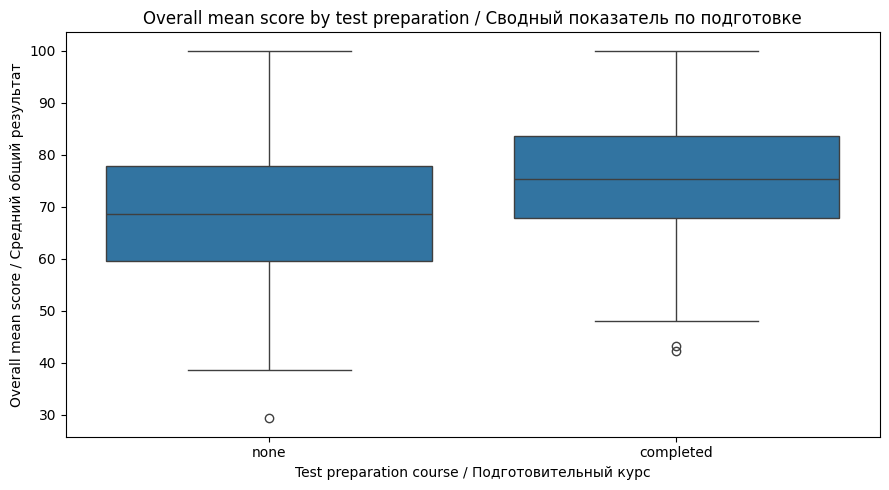

In [ ]:
# 1. BOXPLOT: сводный показатель по группам
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_v8, x="test preparation course", y="overall_mean_score")
plt.title("Overall mean score by test preparation / Сводный показатель по подготовке")
plt.xlabel("Test preparation course / Подготовительный курс")
plt.ylabel("Overall mean score / Средний общий результат")
plt.tight_layout()
plt.show()


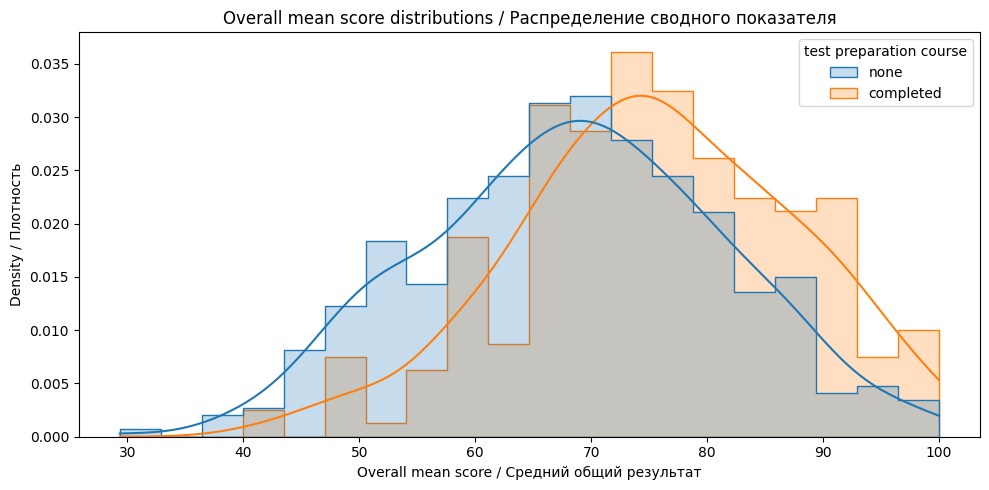

In [ ]:
# 2. HISTPLOT: распределение сводного показателя
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df_v8, x="overall_mean_score",
    hue="test preparation course", bins=20, kde=True,
    element="step", stat="density", common_norm=False
)
plt.title("Overall mean score distributions / Распределение сводного показателя")
plt.xlabel("Overall mean score / Средний общий результат")
plt.ylabel("Density / Плотность")
plt.tight_layout()
plt.show()


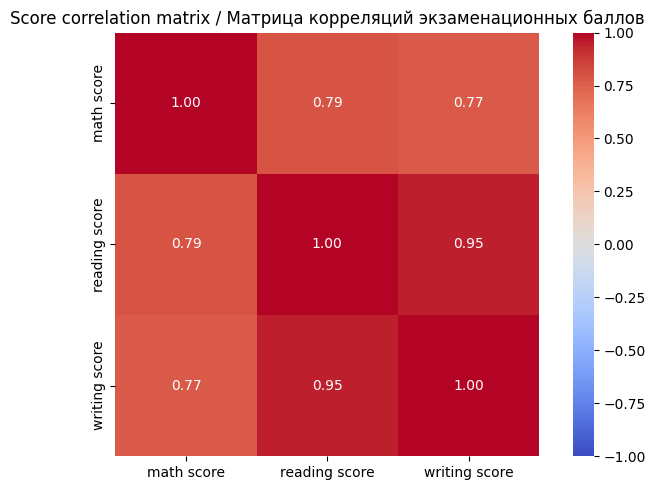

,math score,reading score,writing score
math score,1.000,0.794,0.768
reading score,0.794,1.000,0.948
writing score,0.768,0.948,1.000


In [ ]:
# 3. CORRELATION HEATMAP: корреляции трёх исходных оценок
corr_matrix = df_v8[score_cols].corr(method="pearson")
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", square=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Score correlation matrix / Матрица корреляций экзаменационных баллов")
plt.tight_layout()
plt.show()
display(corr_matrix.round(3))


### Короткое пояснение результата

Boxplot и гистограмма показывают распределение сводного показателя успеваемости в группах `completed` и `none`. Тепловая карта отражает взаимосвязь оценок по математике, чтению и письму. Корреляция описывает совместное изменение показателей, но сама по себе не доказывает причинность.


## Блок 4. Проверка гипотезы варианта № 8

Проверяется односторонняя гипотеза с помощью Welch t-test для независимых групп.

$$H_0: \mu_{completed} \leq \mu_{none}$$
$$H_1: \mu_{completed} > \mu_{none}$$

Уровень значимости: $\alpha=0.05$.

Если $p<0.05$, нулевая гипотеза отклоняется в пользу направленной альтернативы. Иначе статистических оснований для такого вывода недостаточно.


In [ ]:
completed = df_v8.loc[
    df_v8["test preparation course"].eq("completed"),
    "overall_mean_score"
].astype(float)

none_group = df_v8.loc[
    df_v8["test preparation course"].eq("none"),
    "overall_mean_score"
].astype(float)

print("completed: n =", len(completed))
print("none:      n =", len(none_group))
print(f"completed overall mean = {completed.mean():.3f}")
print(f"none overall mean      = {none_group.mean():.3f}")
print(f"mean difference        = {completed.mean() - none_group.mean():.3f}")

try:
    result = stats.ttest_ind(completed, none_group, equal_var=False, alternative="greater")
    t_stat = float(result.statistic)
    p_value = float(result.pvalue)
except TypeError:
    result = stats.ttest_ind(completed, none_group, equal_var=False)
    t_stat = float(result.statistic)
    p_two_sided = float(result.pvalue)
    p_value = p_two_sided / 2 if t_stat > 0 else 1 - p_two_sided / 2

alpha = 0.05
print("\nWelch one-sided t-test")
print(f"t = {t_stat:.4f}")
print(f"p = {p_value:.8g}")
print(f"alpha = {alpha}")


completed: n = 227
none:      n = 416
completed overall mean = 75.505
none overall mean      = 68.497
mean difference        = 7.008

Welch one-sided t-test
t = 6.9142
p = 7.2912293e-12
alpha = 0.05


### Короткое пояснение результата

Результаты Welch t-test оценивают, есть ли статистические основания считать средний сводный показатель группы `completed` выше, чем у группы `none`. 7.2912293 * 10^-12

Для `overall_mean_score` получено:

среднее `completed` — **75,51**;

среднее `none` — **68,50**;

разница — **7,01** балла;

**t = 6,9142;**

**p ≈ 7.3 * 10^-12.**

Так как  p<0.05 , нулевая гипотеза отклоняется в пользу направленной альтернативы: в этой выборке общий средний балл у группы completed выше. Это не означает, что подготовительный курс доказанно является причиной различия.


### Размер эффекта

Статистическая значимость не показывает величину различия. Поэтому дополнительно вычисляется Cohen's $d$:

$$
d=\frac{\bar{x}_1-\bar{x}_2}{s_p},
$$

где $s_p$ — объединённое стандартное отклонение.


In [ ]:
def cohens_d_independent(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    nx = len(x)
    ny = len(y)

    sx2 = np.var(x, ddof=1)
    sy2 = np.var(y, ddof=1)

    pooled_sd = np.sqrt(
        ((nx - 1) * sx2 + (ny - 1) * sy2) /
        (nx + ny - 2)
    )

    if pooled_sd == 0:
        return 0.0

    return (
        np.mean(x) - np.mean(y)
    ) / pooled_sd


d = cohens_d_independent(completed, none_group)

if abs(d) < 0.2:
    magnitude = "very small / очень малый"
elif abs(d) < 0.5:
    magnitude = "small / малый"
elif abs(d) < 0.8:
    magnitude = "medium / средний"
else:
    magnitude = "large / большой"

print(f"Cohen's d = {d:.3f}")
print(
    "Effect magnitude / Размер эффекта:",
    magnitude
)


Cohen's d = 0.558
Effect magnitude / Размер эффекта: medium / средний


### Размер эффекта

Дополнительно рассчитывается Cohen's $d$, чтобы описать стандартизированную величину различия между средними сводными показателями. Этот показатель дополняет p-value, но не заменяет проверку гипотезы.

Получено Cohen's d = 0,558, что в принятой учебной интерпретации соответствует среднему размеру эффекта. То есть различие не только статистически значимо, но и заметно по величине.



### Автоматическая формулировка вывода

Код ниже формирует статистический вывод и отдельно — педагогическую интерпретацию. Это разделение принципиально: статистическая связь в наблюдательном наборе не доказывает причинное влияние подготовительного курса.


In [ ]:
mean_completed = completed.mean()
mean_none = none_group.mean()
difference = mean_completed - mean_none

print("=" * 78)
print("STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД")
print("=" * 78)

if p_value < alpha and difference > 0:
    print(f"p={p_value:.8g} < {alpha}. H0 отклоняется в пользу H1.")
    print(f"Средний сводный показатель: completed={mean_completed:.2f}; none={mean_none:.2f}.")
    print(f"Разница средних = {difference:.2f} балла.")
else:
    print(f"p={p_value:.8g}. Недостаточно оснований подтвердить направленную альтернативную гипотезу.")

print("\nPEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД")
print("В анализируемой выборке можно говорить о статистической связи между прохождением подготовительного курса и общим средним результатом по трём предметам.")
print("Наблюдаемая связь не доказывает причинность: на оценки могли влиять и другие факторы.")
print("Корректная формулировка: в этой выборке группы различаются по среднему общему результату.")


STATISTICAL CONCLUSION / СТАТИСТИЧЕСКИЙ ВЫВОД
p=7.2912293e-12 < 0.05. H0 отклоняется в пользу H1.
Средний сводный показатель: completed=75.51; none=68.50.
Разница средних = 7.01 балла.

PEDAGOGICAL INTERPRETATION / ПЕДАГОГИЧЕСКИЙ ВЫВОД
В анализируемой выборке можно говорить о статистической связи между прохождением подготовительного курса и общим средним результатом по трём предметам.
Наблюдаемая связь не доказывает причинность: на оценки могли влиять и другие факторы.
Корректная формулировка: в этой выборке группы различаются по среднему общему результату.


### Итог варианта № 8

В анализируемой выборке прохождение подготовительного курса связано с более высоким общий средним результатом по трём предметам: средняя разница составляет около 7,01 балла. Результат статистически значим, а размер эффекта — средний.

Корректный педагогический вывод: данные дают основание говорить о различии групп, но не позволяют утверждать, что именно курс вызвал повышение баллов.


## Дополнительное задание. Повторение расчётов в BigQuery

Цель дополнительного задания — убедиться, что ключевые агрегаты можно получить не только в `pandas`, но и средствами GoogleSQL.

Чтобы результаты совпадали с Colab, в BigQuery загружается **уже очищенная таблица `df_clean`**.

In [ ]:
# Подготовка CSV с удобными для BigQuery именами столбцов.
bq_export = df_clean.rename(columns={
    "race/ethnicity": "race_ethnicity",
    "parental level of education": "parental_education",
    "test preparation course": "test_preparation",
    "math score": "math_score",
    "reading score": "reading_score",
    "writing score": "writing_score",
}).copy()

BQ_CSV = "students_performance_lab01_clean.csv"
bq_export.to_csv(BQ_CSV, index=False)

print("Файл для BigQuery:", BQ_CSV)
print("Строк:", len(bq_export))
print("Столбцов:", len(bq_export.columns))


Файл для BigQuery: students_performance_lab01_clean.csv
Строк: 993
Столбцов: 8


### Загрузка в BigQuery

1. Откройте `https://console.cloud.google.com/bigquery`.
2. Используйте существующий Google Cloud Project или создайте новый, если проекта ещё нет.
3. В **Explorer** создайте dataset, например `learning_analytics`.
4. Откройте dataset → **Create table**.
5. Выберите файл `students_performance_lab01_clean.csv`.
6. **File format:** `CSV`.
7. **Table:** `students_performance`.
8. Включите **Schema → Auto detect**.
9. В **Advanced options** задайте **Header rows to skip = 1**.
10. После создания проверьте **Schema** и **Preview**.

В запросах ниже замените `YOUR_PROJECT_ID` на идентификатор своего проекта.

### SQL 1. Контроль числа строк

```sql
SELECT
  COUNT(*) AS rows_count
FROM `concise-forge-508714-i8.learning_analytics.students_performance`;
```

Ожидаемый результат: 993.

Реальный результат:

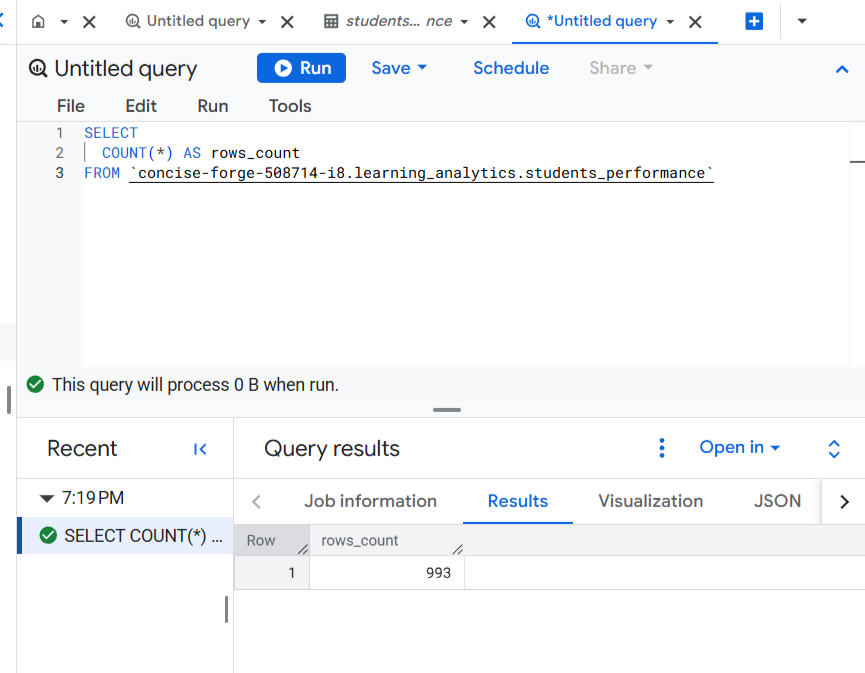

Это подтверждает, что в BigQuery загружена та же очищенная таблица, которая использовалась в Colab.

### SQL 2. Сводный показатель варианта № 8

```sql
SELECT
  test_preparation,
  COUNT(*) AS n,
  ROUND(AVG((math_score + reading_score + writing_score) / 3), 2) AS overall_mean_score
FROM `concise-forge-508714-i8.learning_analytics.students_performance`
WHERE lunch = 'standard'
GROUP BY test_preparation
ORDER BY test_preparation;
```

**Ожидаемый результат:**

| test_preparation | n | overall_mean_score |
|---|---:|---:|
| `completed` | 227 | 75.51 |
| `none` | 416 | 68.50 |

**Пояснение:** BigQuery воспроизводит те же групповые средние, что и `pandas`.

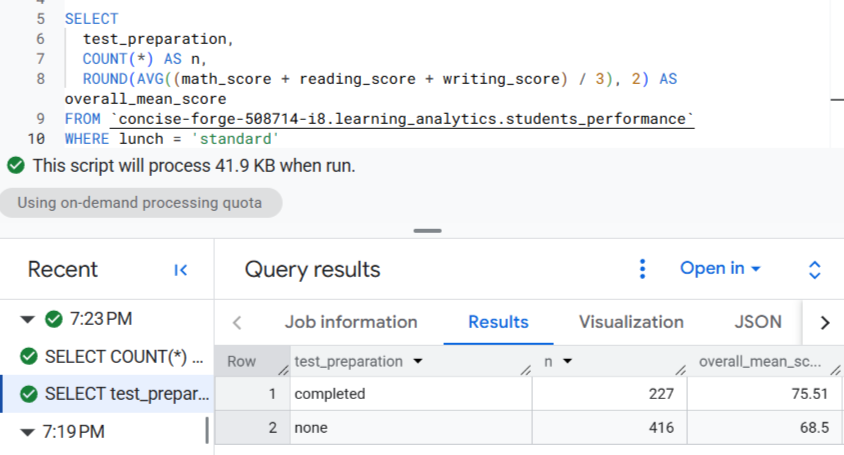



### SQL 3. Разница средних сводного показателя

```sql
SELECT
  ROUND(
    AVG(IF(test_preparation = 'completed',
      (math_score + reading_score + writing_score) / 3, NULL))
    -
    AVG(IF(test_preparation = 'none',
      (math_score + reading_score + writing_score) / 3, NULL)),
    2
  ) AS overall_mean_difference
FROM `YOUR_PROJECT_ID.learning_analytics.students_performance`
WHERE lunch = 'standard';
```

**Ожидаемый результат:** 7,01 балла;

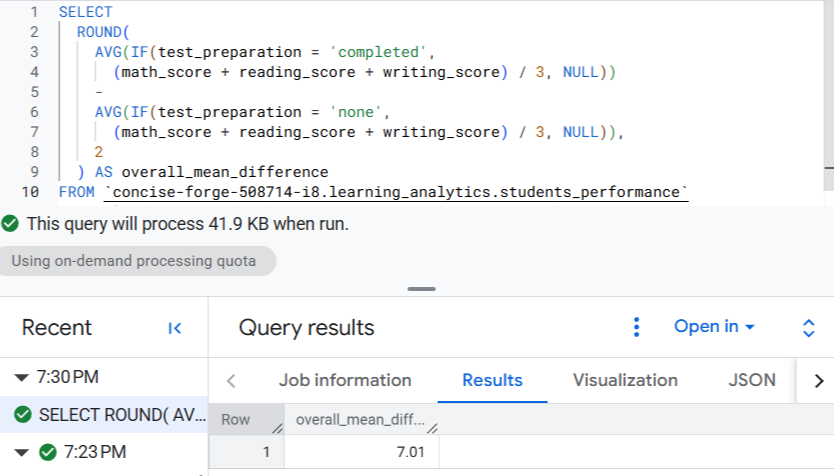

Это то же различие, которое было получено в Colab.

### SQL 4. Корреляции экзаменационных результатов

```sql
SELECT
  ROUND(CORR(math_score, reading_score), 3) AS corr_math_reading,
  ROUND(CORR(math_score, writing_score), 3) AS corr_math_writing,
  ROUND(CORR(reading_score, writing_score), 3) AS corr_reading_writing
FROM `concise-forge-508714-i8.learning_analytics.students_performance`
WHERE lunch = 'standard';
```

**Ожидаемо:** наиболее сильная связь — между `reading_score` и `writing_score`, около **0,948**.

> В BigQuery в этой лабораторной достаточно повторить **описательные расчёты**. Welch t-test остаётся основной статистической проверкой в Colab.

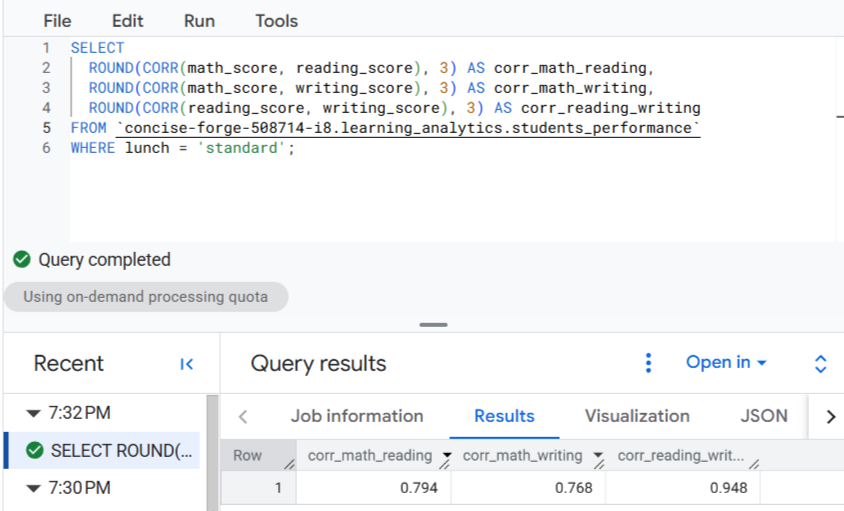

### Что приложить по BigQuery

В отчёте достаточно:

1. текста выполненных SQL-запросов;
2. одного скриншота таблицы или результата запросов;
3. короткой фразы: совпали ли результаты BigQuery с результатами Colab.

______________________________________________________________________
1. Тексты выполненных запросов выше.
2. Скриншоты выполнений вставлены под каждым пунктом проверки.
3. Результаты BigQuery совпали с результатами Colab.

## Дидактический вывод для интегрированного занятия

Вариант №8 удобно использовать как микроурок «Информатика + английский язык».

Школьники:

1. читают англоязычные названия признаков;
2. фильтруют таблицу;
3. строят boxplot, histogram и heatmap;
4. сравнивают средние;
5. формулируют вывод на русском и английском языке;
6. обсуждают разницу между `association` (ассоциация) и `causation` (причинность).

Корректная фраза:

> `Students who completed test preparation show higher overall scores in this sample.`

Некорректная:

> `The preparation course always causes better performance.`

Таким образом, упражнение развивает одновременно алгоритмическое мышление, статистическую грамотность и академический английский язык.



## Контроль воспроизводимости

Последняя ячейка проверяет ключевые условия решения.


In [18]:
expected_columns = {
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score",
    "writing score",
}

assert expected_columns.issubset(df_raw.columns)
assert len(df_raw) > 0
assert df_clean[score_cols].notna().all().all()

assert (
    df_v8["lunch"] == "standard"
).all()

present_groups = set(
    df_v8["test preparation course"].unique()
)

assert {"completed", "none"}.issubset(
    present_groups
)

assert len(completed) >= 2
assert len(none_group) >= 2

print(
    "All checks passed / Все проверки пройдены."
)
print(
    "Notebook is ready for Google Colab / "
    "Ноутбук готов к запуску в Google Colab."
)


All checks passed / Все проверки пройдены.
Notebook is ready for Google Colab / Ноутбук готов к запуску в Google Colab.


---
## Оценивание лабораторной работы — 10 баллов

| Критерий | Баллы |
|---|---:|
| Загрузка, проверка и очистка данных в Colab | **2** |
| Индивидуальный анализ и описательная статистика | **2** |
| Визуализации | **1** |
| Проверка гипотезы и корректный статистический вывод | **2** |
| Дополнительные расчёты в BigQuery и сопоставление с Colab | **2** |
| Методический блок и оформление notebook | **1** |
| **Итого** | **10** |